# Student Performance Analysis and Prediction System
**Dataset notice:** bundled data is synthetic demonstration data. Replace with a sourced dataset before final submission.


In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn


In [2]:
from pathlib import Path
import pandas as pd
DATA = Path('/content/student_performance_dataset.csv')
df = pd.read_csv(DATA)
df.head()


FileNotFoundError: [Errno 2] No such file or directory: '/content/student_performance_dataset.csv'

In [5]:
import os
print(os.listdir('/content'))

['.config', 'sample_data']


In [7]:
from google.colab import files
uploaded = files.upload()

Saving student_performance_dataset (1).csv to student_performance_dataset (1).csv


In [9]:
import os
print(os.listdir('/content'))

['.config', 'student_performance_dataset (1).csv', 'sample_data']


In [12]:
import pandas as pd
df = pd.read_csv('/content/student_performance_dataset(1).csv')
print('dataset fully loaded!')
df.head()

FileNotFoundError: [Errno 2] No such file or directory: '/content/student_performance_dataset(1).csv'

In [13]:
import pandas as pd
import glob
files = glob.glob('/content/*.csv')
print('csv files found",files)
if files:
      df = pd.read_csv(files[0])
      print("dataset succesfully loaded!")
      display(df.head())
else:
      print("csv file not found. please upload again.")

SyntaxError: unterminated string literal (detected at line 4) (3426127347.py, line 4)

Run the complete pipeline from the project root using `python src/model.py`. The script saves evaluation metrics, predictions and visualizations in `outputs/`.


In [14]:
import pandas as pd
import glob

files = glob.glob('/content/*.csv')

print("CSV Files Found:", files)

if files:
    df = pd.read_csv(files[0])
    print("Dataset Successfully Loaded!")
    display(df.head())
else:
    print("CSV file not found. Please upload again.")

CSV Files Found: ['/content/student_performance_dataset (1).csv']
Dataset Successfully Loaded!


,student_id,study_hours_per_day,attendance_percent,previous_exam_marks,final_exam_marks
0,S001,3.6,75.8,62.1,58.4
1,S002,3.6,58.5,69.6,50.3
2,S003,3.5,79.5,67.9,64.9
3,S004,4.7,79.4,51.4,44.4
4,S005,4.1,95.0,64.7,58.4


In [15]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (301, 5)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   student_id           301 non-null    object 
 1   study_hours_per_day  301 non-null    float64
 2   attendance_percent   300 non-null    float64
 3   previous_exam_marks  300 non-null    float64
 4   final_exam_marks     301 non-null    float64
dtypes: float64(4), object(1)
memory usage: 11.9+ KB

Missing Values:
student_id             0
study_hours_per_day    0
attendance_percent     1
previous_exam_marks    1
final_exam_marks       0
dtype: int64

Statistical Summary:


,study_hours_per_day,attendance_percent,previous_exam_marks,final_exam_marks
count,301.000000,300.000000,300.000000,301.000000
mean,3.850498,77.026667,63.377000,53.857807
std,1.297937,12.677559,17.161746,11.922650
min,0.500000,44.400000,10.400000,16.000000
25%,2.900000,68.875000,52.250000,44.600000
50%,3.800000,78.000000,64.400000,53.900000
75%,4.800000,84.600000,74.100000,62.400000
max,8.000000,100.000000,100.000000,82.400000


In [16]:
# Check missing values
print("Missing Values Before Cleaning:")
print(df.isnull().sum())

# Remove duplicate rows
df = df.drop_duplicates()

# Fill missing numeric values with column mean
numeric_cols = df.select_dtypes(include='number').columns

for col in numeric_cols:
    df[col] = df[col].fillna(df[col].mean())

# Check missing values again
print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

print("\nDataset Shape After Cleaning:", df.shape)

Missing Values Before Cleaning:
student_id             0
study_hours_per_day    0
attendance_percent     1
previous_exam_marks    1
final_exam_marks       0
dtype: int64

Missing Values After Cleaning:
student_id             0
study_hours_per_day    0
attendance_percent     0
previous_exam_marks    0
final_exam_marks       0
dtype: int64

Dataset Shape After Cleaning: (300, 5)


In [17]:
df.to_csv('/content/student_performance_cleaned.csv', index=False)

print("Cleaned Dataset Successfully Saved!")

Cleaned Dataset Successfully Saved!


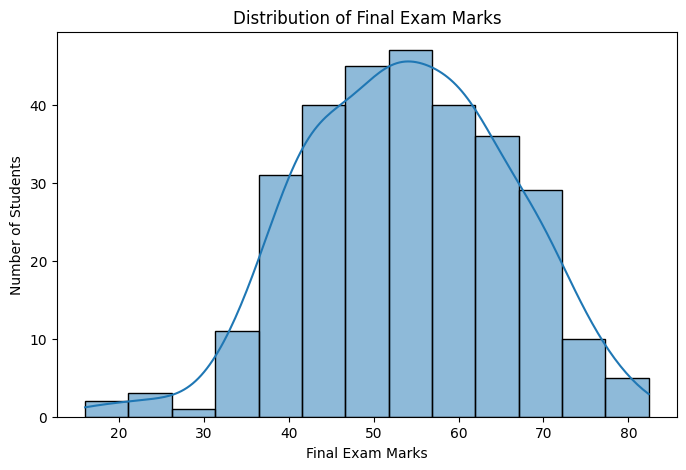

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))

sns.histplot(data=df, x='final_exam_marks', kde=True)

plt.title('Distribution of Final Exam Marks')
plt.xlabel('Final Exam Marks')
plt.ylabel('Number of Students')

plt.show()

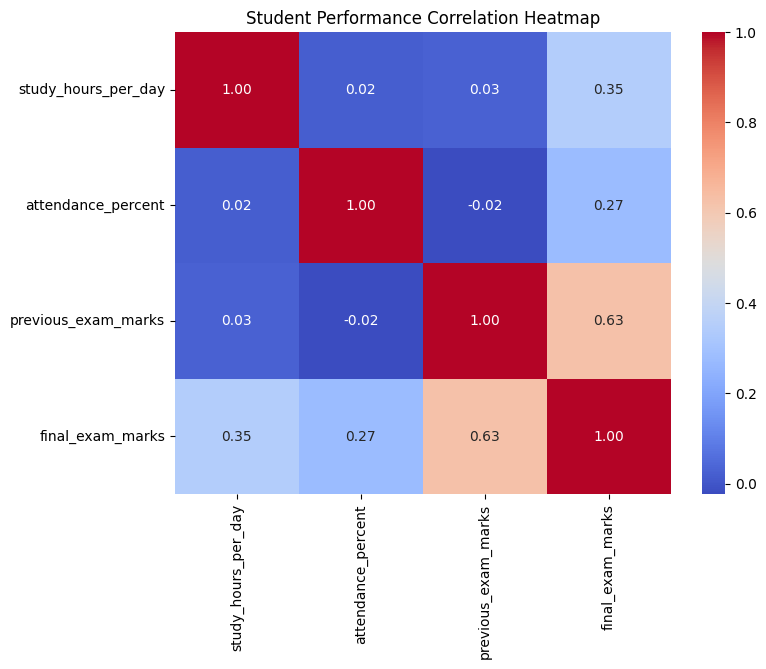

In [19]:
plt.figure(figsize=(8,6))

correlation = df.select_dtypes(include='number').corr()

sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Student Performance Correlation Heatmap')

plt.show()

In [20]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Select input and output
X = df[['study_hours_per_day',
        'attendance_percent',
        'previous_exam_marks']]

y = df['final_exam_marks']

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train model
model = LinearRegression()
model.fit(X_train, y_train)

print("Model Trained Successfully!")

Model Trained Successfully!


In [21]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Make predictions
y_pred = model.predict(X_test)

# Evaluate model
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", mae)
print("Root Mean Squared Error:", rmse)
print("R2 Score:", r2)

Mean Absolute Error: 6.879695755110409
Root Mean Squared Error: 8.282413163720843
R2 Score: 0.4999825282650434


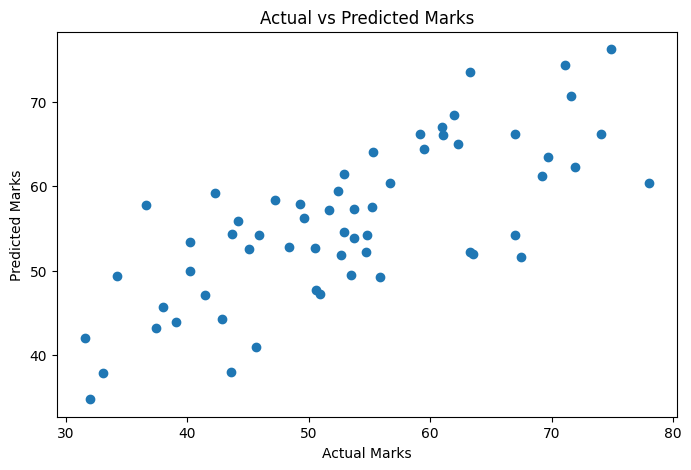

In [22]:
plt.figure(figsize=(8,5))

plt.scatter(y_test, y_pred)

plt.xlabel('Actual Marks')
plt.ylabel('Predicted Marks')

plt.title('Actual vs Predicted Marks')

plt.show()

In [23]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(
    model, X, y, cv=5, scoring='r2'
)

print("Cross Validation Scores:", scores)

print("Average R2 Score:", scores.mean())

Cross Validation Scores: [0.56032683 0.4895075  0.496774   0.53019359 0.6407733 ]
Average R2 Score: 0.5435150425597377


In [24]:
print("Cross Validation Scores:")
for score in scores:
    print(round(score, 4))

print("Average R2 Score:", round(scores.mean(), 4))

Cross Validation Scores:
0.5603
0.4895
0.4968
0.5302
0.6408
Average R2 Score: 0.5435


Conclusion
The Student Performance Analysis and Prediction System was developed using Python and Machine Learning.
The project involved:
Data Cleaning using Pandas.
Exploratory Data Analysis (EDA).
Data Visualization using Matplotlib and Seaborn.
Linear Regression Model Training.
Model Evaluation using MAE, RMSE and R² Score.
Five-Fold Cross Validation.
The model achieved an average R² score of 0.5435 during cross-validation.
Limitation: The project uses a synthetic sample dataset, so the results should not be treated as real-world educational findings.

In [25]:
readme = """
# Student Performance Analysis and Prediction System

## Project Overview
This project analyzes student performance and predicts
final exam marks using Machine Learning.

## Technologies Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Google Colab

## Dataset
The dataset contains 300 student records and 5 columns.

## Machine Learning Algorithm
Linear Regression

## Model Evaluation
MAE: 6.8797
RMSE: 8.2824
R2 Score: 0.5000

Average Cross Validation R2 Score: 0.5435

## Conclusion
The model identifies patterns in student performance
using study hours, attendance and previous exam marks.

Note: The dataset is synthetic and intended for
educational demonstration only.
"""

with open('/content/README.md', 'w') as f:
    f.write(readme)

print("README File Created Successfully!")

README File Created Successfully!


In [26]:
from google.colab import files

files.download('/content/README.md')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>